In [1]:
!pip -q install tokenizers gensim scikit-learn matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

np.random.seed(0)

In [2]:
# Pula 1: "zamek" jako budowla
zdania_zamek_budowla = [
    'Król zbudował potężny zamek na wzgórzu.',
    'Zwiedzaliśmy stary zamek z przewodnikiem.',
    'Ten zamek ma wysokie wieże i gruby mur.',
    'Rycerze bronili dostępu do zamku przed wrogiem.',
    'W średniowieczu zamek był twierdzą nie do zdobycia.'
] * 4

# Pula 2: "zamek" jako mechanizm
zdania_zamek_mechanizm = [
    'Ślusarz wymienił zepsuty zamek w drzwiach.',
    'Przekręciłem klucz, ale zamek się zaciął.',
    'Nowy zamek antywłamaniowy jest bardzo bezpieczny.',
    'Ktoś uszkodził zamek w mojej szafce.',
    'Zamek błyskawiczny w kurtce zepsuł się na mrozie.'
] * 4

# Pula 3: Zdania tła (bez słowa "zamek", słownictwo mieszane)
zdania_tlo = [
    'Klucz leżał na drewnianym stole w kuchni.',
    'Stare drzwi skrzypiały przy każdym otwarciu.',
    'Wysoka wieża była widoczna z wielu kilometrów.',
    'Król wydał nowy dekret dla swoich poddanych.',
    'Ślusarz użył specjalistycznych narzędzi do naprawy.',
    'Rycerze założyli ciężkie zbroje i ruszyli do walki.',
    'Uczenie maszynowe analizuje duże zbiory tekstów.',
    'Tokenizacja to pierwszy krok w przetwarzaniu języka.'
] * 3

# Połączenie i wymieszanie korpusu (~64 zdania)
KORPUS = zdania_zamek_budowla + zdania_zamek_mechanizm + zdania_tlo
np.random.shuffle(KORPUS)

print('Liczba zdań w korpusie:', len(KORPUS))

Liczba zdań w korpusie: 64


In [3]:
# Trening tokenizera
tok = Tokenizer(models.BPE(unk_token='[UNK]'))
tok.pre_tokenizer = pre_tokenizers.Whitespace()

# Zgodnie z zadaniem możesz tu testować różne limity (np. 100, 300, 500)
LIMIT_SLOWNIKA = 300
trainer = trainers.BpeTrainer(vocab_size=LIMIT_SLOWNIKA, special_tokens=['[UNK]'], min_frequency=1)
tok.train_from_iterator(KORPUS, trainer)

print('Faktyczny rozmiar słownika BPE:', tok.get_vocab_size())

# Pary form (widziane w korpusie vs niewidziane)
formy_testowe = [
    ('zamek', 'zamkami'),      # rdzeń wieloznaczny
    ('rycerze', 'rycerzom'),   # z puli budowli
    ('ślusarz', 'ślusarzem'),  # z puli mechanizmu
    ('wieże', 'wieżach'),      # z puli budowli
    ('klucz', 'kluczami')      # z puli mechanizmu
]

print("\nPodział BPE dla testowych form fleksyjnych:")
for forma_widziana, forma_niewidziana in formy_testowe:
    print(f"  Widziana:    {forma_widziana:12s} -> {tok.encode(forma_widziana).tokens}")
    print(f"  Niewidziana: {forma_niewidziana:12s} -> {tok.encode(forma_niewidziana).tokens}")
    print("-" * 45)

Faktyczny rozmiar słownika BPE: 300

Podział BPE dla testowych form fleksyjnych:
  Widziana:    zamek        -> ['zamek']
  Niewidziana: zamkami      -> ['za', 'm', 'ka', 'm', 'i']
---------------------------------------------
  Widziana:    rycerze      -> ['ry', 'cerze']
  Niewidziana: rycerzom     -> ['ry', 'ce', 'rz', 'o', 'm']
---------------------------------------------
  Widziana:    ślusarz      -> ['ś', 'lu', 'sarz']
  Niewidziana: ślusarzem    -> ['ś', 'lu', 's', 'a', 'rze', 'm']
---------------------------------------------
  Widziana:    wieże        -> ['wieże']
  Niewidziana: wieżach      -> ['wie', 'ż', 'ach']
---------------------------------------------
  Widziana:    klucz        -> ['klucz']
  Niewidziana: kluczami     -> ['k', 'lu', 'c', 'za', 'm', 'i']
---------------------------------------------


In [7]:
def testuj_bpe_dla_rozmiarow(rozmiary):
    for limit in rozmiary:
        test_tok = Tokenizer(models.BPE(unk_token='[UNK]'))
        test_tok.pre_tokenizer = pre_tokenizers.Whitespace()
        trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
        test_tok.train_from_iterator(KORPUS, trainer)

        print(f"=== LIMIT SŁOWNIKA: {limit} (Faktyczny: {test_tok.get_vocab_size()}) ===")
        for forma_widziana, forma_niewidziana in formy_testowe:
            print(f"  Widziana:    {forma_widziana:12s} -> {test_tok.encode(forma_widziana).tokens}")
            print(f"  Niewidziana: {forma_niewidziana:12s} -> {test_tok.encode(forma_niewidziana).tokens}")
        print("\n" + "="*50 + "\n")

# Przeprowadzenie analizy dla trzech różnych rozmiarów
testuj_bpe_dla_rozmiarow([50, 150, 500])

=== LIMIT SŁOWNIKA: 50 (Faktyczny: 50) ===
  Widziana:    zamek        -> ['zamek']
  Niewidziana: zamkami      -> ['za', 'm', 'k', 'a', 'm', 'i']
  Widziana:    rycerze      -> ['r', 'y', 'c', 'e', 'rz', 'e']
  Niewidziana: rycerzom     -> ['r', 'y', 'c', 'e', 'rz', 'o', 'm']
  Widziana:    ślusarz      -> ['ś', 'l', 'u', 's', 'a', 'rz']
  Niewidziana: ślusarzem    -> ['ś', 'l', 'u', 's', 'a', 'rz', 'e', 'm']
  Widziana:    wieże        -> ['w', 'ie', 'ż', 'e']
  Niewidziana: wieżach      -> ['w', 'ie', 'ż', 'a', 'c', 'h']
  Widziana:    klucz        -> ['k', 'l', 'u', 'c', 'z']
  Niewidziana: kluczami     -> ['k', 'l', 'u', 'c', 'za', 'm', 'i']


=== LIMIT SŁOWNIKA: 150 (Faktyczny: 150) ===
  Widziana:    zamek        -> ['zamek']
  Niewidziana: zamkami      -> ['za', 'm', 'ka', 'm', 'i']
  Widziana:    rycerze      -> ['r', 'y', 'cerze']
  Niewidziana: rycerzom     -> ['r', 'y', 'ce', 'rz', 'o', 'm']
  Widziana:    ślusarz      -> ['ś', 'lu', 'sarz']
  Niewidziana: ślusarzem    -> [

In [4]:
# Przygotowanie danych (małe litery, usunięcie kropek)
zdania_w2v = [[w.lower() for w in s.replace('.', '').split()] for s in KORPUS]

# Trening modelu Skip-gram
w2v = Word2Vec(zdania_w2v, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=0, workers=1)

print('Liczba unikalnych słów w modelu:', len(w2v.wv))

# Szukamy sąsiadów dla naszego wieloznacznego słowa "zamek"
slowo_badane = 'zamek'
if slowo_badane in w2v.wv:
    print(f"\nNajbliżsi sąsiedzi dla słowa '{slowo_badane}':")
    dopasowania = w2v.wv.most_similar(slowo_badane, topn=5)
    for sasiad, cosinus in dopasowania:
        print(f"  {sasiad:12s} : {cosinus:.3f}")
else:
    print(f"Słowo '{slowo_badane}' nie występuje w słowniku przy obecnym min_count.")

Liczba unikalnych słów w modelu: 95

Najbliżsi sąsiedzi dla słowa 'zamek':
  się          : 0.861
  zaciął       : 0.853
  błyskawiczny : 0.843
  klucz,       : 0.835
  ale          : 0.834


In [8]:
# Tworzymy wariant zdominowany przez znaczenie budowli (np. stosunek 8:1)
KORPUS_DOMINACJA_BUDOWLI = zdania_zamek_budowla * 2 + zdania_zamek_mechanizm[:5] + zdania_tlo
np.random.shuffle(KORPUS_DOMINACJA_BUDOWLI)

zdania_w2v_dominacja = [[w.lower() for w in s.replace('.', '').split()] for s in KORPUS_DOMINACJA_BUDOWLI]
w2v_dominacja = Word2Vec(zdania_w2v_dominacja, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=0, workers=1)

print('Liczba zdań w nowym korpusie:', len(KORPUS_DOMINACJA_BUDOWLI))
print('Liczba unikalnych słów w zdominowanym modelu:', len(w2v_dominacja.wv))

if 'zamek' in w2v_dominacja.wv:
    print("\nNajbliżsi sąsiedzi dla słowa 'zamek' w korpusie zdominowanym przez budowle:")
    dopasowania_dom = w2v_dominacja.wv.most_similar('zamek', topn=5)
    for sasiad, cosinus in dopasowania_dom:
        print(f"  {sasiad:12s} : {cosinus:.3f}")

Liczba zdań w nowym korpusie: 69
Liczba unikalnych słów w zdominowanym modelu: 76

Najbliżsi sąsiedzi dla słowa 'zamek' w korpusie zdominowanym przez budowle:
  mur          : 0.707
  ten          : 0.706
  wysokie      : 0.700
  wieże        : 0.700
  się          : 0.698


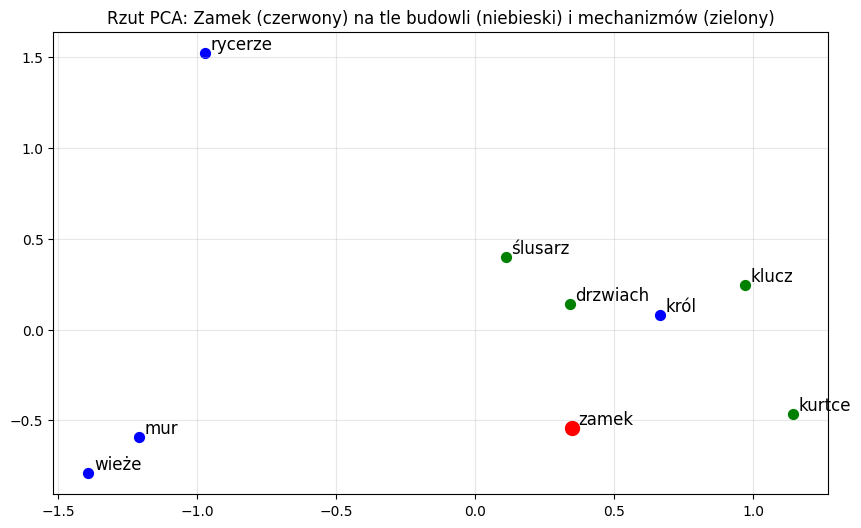

In [5]:
# Słowa do rzutu PCA (nasz badany wyraz + po 4 słowa dla każdego znaczenia)
slowa_budowla = ['wieże', 'mur', 'król', 'rycerze']
slowa_mechanizm = ['drzwiach', 'klucz', 'ślusarz', 'kurtce']
slowa_pca = [slowo_badane] + slowa_budowla + slowa_mechanizm

# Filtrowanie tylko tych słów, które faktycznie są w modelu
slowa_obecne = [w for w in slowa_pca if w in w2v.wv]

V = np.stack([w2v.wv[w] for w in slowa_obecne])
XY = PCA(n_components=2, random_state=0).fit_transform(V)

plt.figure(figsize=(10, 6))

# Rysowanie punktów z różnymi kolorami dla grup
for i, w in enumerate(slowa_obecne):
    x, y = XY[i, 0], XY[i, 1]
    if w == slowo_badane:
        kolor = 'red'
        rozmiar = 100
    elif w in slowa_budowla:
        kolor = 'blue'
        rozmiar = 50
    else:
        kolor = 'green'
        rozmiar = 50

    plt.scatter(x, y, color=kolor, s=rozmiar)
    plt.annotate(w, (x + 0.02, y + 0.02), fontsize=12)

plt.title("Rzut PCA: Zamek (czerwony) na tle budowli (niebieski) i mechanizmów (zielony)")
plt.grid(alpha=0.3)
plt.show()

In [9]:
print("Porównanie odległości PCA (2D) z pełnymi podobieństwami cosinusowymi (50D):\n")
for slowo in slowa_obecne:
    if slowo == slowo_badane:
        continue

    # Pełna przestrzeń
    pelne_podobienstwo = w2v.wv.similarity(slowo_badane, slowo)

    # Odległość euklidesowa na rzucie PCA
    idx_zamek = slowa_obecne.index(slowo_badane)
    idx_slowo = slowa_obecne.index(slowo)
    odleglosc_pca = np.linalg.norm(XY[idx_zamek] - XY[idx_slowo])

    print(f"Słowo: {slowo:12s} | Podobieństwo cosinusowe (50D): {pelne_podobienstwo:.3f} | Odległość na wykresie PCA (2D): {odleglosc_pca:.3f}")

Porównanie odległości PCA (2D) z pełnymi podobieństwami cosinusowymi (50D):

Słowo: wieże        | Podobieństwo cosinusowe (50D): 0.642 | Odległość na wykresie PCA (2D): 1.758
Słowo: mur          | Podobieństwo cosinusowe (50D): 0.647 | Odległość na wykresie PCA (2D): 1.560
Słowo: król         | Podobieństwo cosinusowe (50D): 0.645 | Odległość na wykresie PCA (2D): 0.694
Słowo: rycerze      | Podobieństwo cosinusowe (50D): 0.216 | Odległość na wykresie PCA (2D): 2.451
Słowo: drzwiach     | Podobieństwo cosinusowe (50D): 0.801 | Odległość na wykresie PCA (2D): 0.684
Słowo: klucz        | Podobieństwo cosinusowe (50D): 0.612 | Odległość na wykresie PCA (2D): 1.005
Słowo: ślusarz      | Podobieństwo cosinusowe (50D): 0.633 | Odległość na wykresie PCA (2D): 0.970
Słowo: kurtce       | Podobieństwo cosinusowe (50D): 0.831 | Odległość na wykresie PCA (2D): 0.796


Uwaga (attention) dla zapytania 'zamek' w kontekście zdania:
  zamek        0.187
  w            0.180
  wymienił     0.159
  drzwiach     0.159
  zepsuty      0.158
  ślusarz      0.157


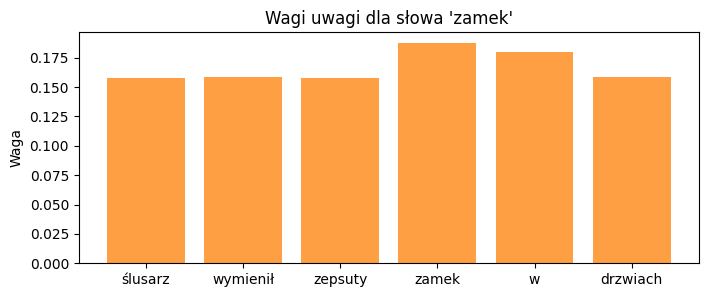

In [6]:
def softmax(x):
    e = np.exp(x - x.max())
    return e / e.sum()

# Zmienione zdanie testowe z naszego korpusu
zdanie_testowe = ['ślusarz', 'wymienił', 'zepsuty', 'zamek', 'w', 'drzwiach']
zdanie_obecne = [w for w in zdanie_testowe if w in w2v.wv]

K = np.stack([w2v.wv[w] for w in zdanie_obecne])
q = w2v.wv['zamek']  # Zapytanie (Query)

scores = (K @ q) / np.sqrt(K.shape[1])
wagi = softmax(scores)
kontekst = wagi @ K

print("Uwaga (attention) dla zapytania 'zamek' w kontekście zdania:")
for w, a in sorted(zip(zdanie_obecne, wagi), key=lambda z: -z[1]):
    print(f"  {w:12s} {a:.3f}")

plt.figure(figsize=(8,3))
plt.bar(zdanie_obecne, wagi, color='#ff9f43')
plt.title("Wagi uwagi dla słowa 'zamek'")
plt.ylabel("Waga")
plt.show()